Clusters: 2 | Noise points: 0


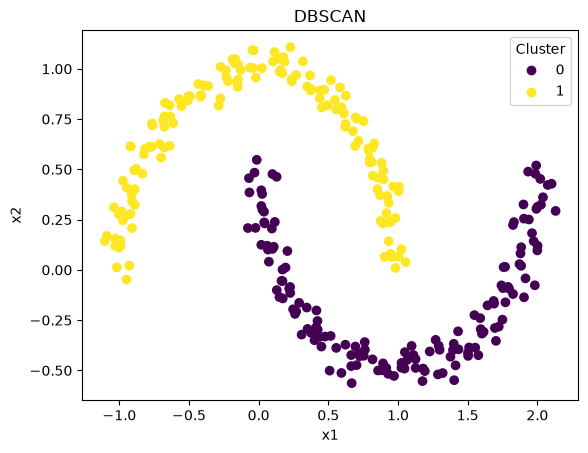

0.1 7 13
0.2 2 0
0.3 2 0
0.5 1 0


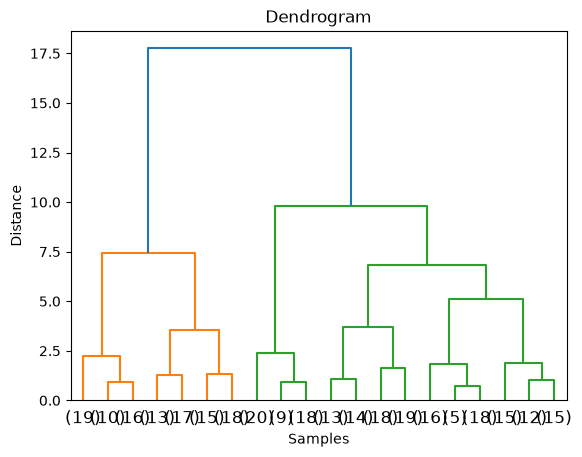

In [1]:
# ===================== REVISION / ONE-SHOT: DBSCAN + AGGLOMERATIVE =====================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

# 1) 2D data
X, _ = make_moons(n_samples=300, noise=0.05, random_state=42)

# 2) DBSCAN: label -1 = noise
model = DBSCAN(eps=0.2, min_samples=5)
labels = model.fit_predict(X)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
print("Clusters:", n_clusters, "| Noise points:", list(labels).count(-1))

# 3) Plot clusters (noise shows as its own colour, label -1)
sc = plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.legend(*sc.legend_elements(), title="Cluster"); plt.title("DBSCAN"); plt.xlabel("x1"); plt.ylabel("x2"); plt.show()

# 4) Parametric analysis: loop eps (or min_samples), record n_clusters / noise / silhouette
for eps in [0.1, 0.2, 0.3, 0.5]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    print(eps, len(set(lab)) - (1 if -1 in lab else 0), list(lab).count(-1))

# 5) Agglomerative + dendrogram
agg_labels = AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(X)
dendrogram(linkage(X, method="ward"), truncate_mode="lastp", p=20)
plt.title("Dendrogram"); plt.xlabel("Samples"); plt.ylabel("Distance"); plt.show()

# ---------------- VIVA NOTES ----------------
# DBSCAN: eps = neighbourhood radius, min_samples (minPts) = points needed to form a dense core.
# Point types: core (>= minPts in eps), border (near core), noise (label -1).
# Finds any-shape clusters, no need to give k, handles outliers; struggles with varying density.
# Small eps -> many noise points / many tiny clusters; large eps -> everything merges into one.
# Large minPts -> stricter density -> more noise. Scale features before DBSCAN.
# Dendrogram: cut horizontally at a big vertical gap; number of lines crossed = number of clusters.

### Q15

Develop a Python program to implement DBSCAN using the sklearn library. Use a 2D dataset (ex. make_moons) for clustering.

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN, KMeans

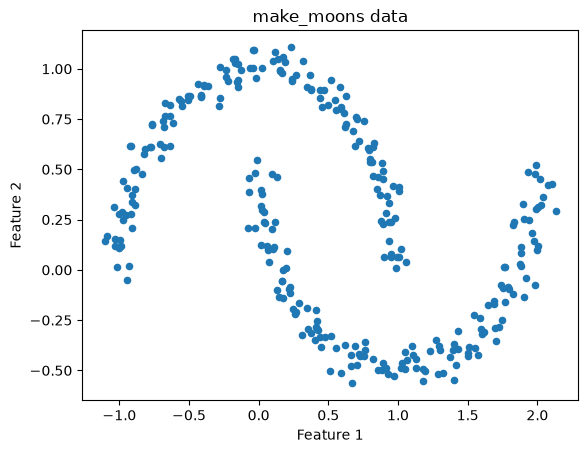

In [3]:
# 2D moon shaped data
X, y = make_moons(n_samples=300, noise=0.05, random_state=42)
plt.scatter(X[:, 0], X[:, 1], s=20)
plt.title("make_moons data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [4]:
# DBSCAN
model = DBSCAN(eps=0.2, min_samples=5)
labels = model.fit_predict(X)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
print("Clusters found:", n_clusters)
print("Noise points:", list(labels).count(-1))

Clusters found: 2
Noise points: 0


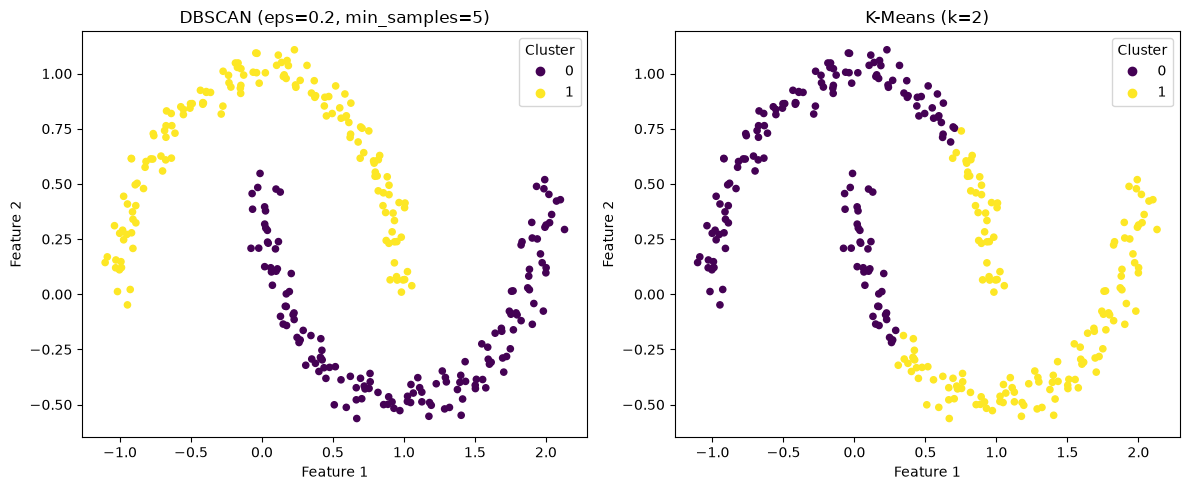

In [5]:
# Plot DBSCAN result next to K-Means (K-Means fails on moon shapes)
km_labels = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sc = ax[0].scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=20)
ax[0].legend(*sc.legend_elements(), title="Cluster")
ax[0].set_title("DBSCAN (eps=0.2, min_samples=5)")
ax[0].set_xlabel("Feature 1")
ax[0].set_ylabel("Feature 2")
sc = ax[1].scatter(X[:, 0], X[:, 1], c=km_labels, cmap="viridis", s=20)
ax[1].legend(*sc.legend_elements(), title="Cluster")
ax[1].set_title("K-Means (k=2)")
ax[1].set_xlabel("Feature 1")
ax[1].set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

### Q16

Generate a random dataset with 5 columns and use 3rd and 4th column as data to implement DBSCAN. Consider eps=5 and minPts=5.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import DBSCAN

In [7]:
# Random dataset with 5 columns (200 rows)
X_all, _ = make_blobs(n_samples=200, n_features=5, centers=3, cluster_std=2.0,
                      center_box=(-30, 30), random_state=42)
df = pd.DataFrame(X_all, columns=["col1", "col2", "col3", "col4", "col5"])
print(df.head())

        col1       col2       col3       col4       col5
0  -9.261885  28.278140  16.353778   6.372086 -18.944079
1  -6.621720  26.710737  14.349514   1.874879 -22.524995
2 -25.472136  26.180412  18.632092 -19.134365 -22.430060
3 -21.261777 -27.768032  17.586309   7.769705  10.508483
4  -7.090316  28.806380  11.901466   2.752921 -19.091481


In [8]:
# Use 3rd and 4th columns (index 2 and 3)
X = df.iloc[:, 2:4].values
model = DBSCAN(eps=5, min_samples=5)
labels = model.fit_predict(X)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
print("Clusters found:", n_clusters)
print("Noise points:", list(labels).count(-1))

Clusters found: 2
Noise points: 0


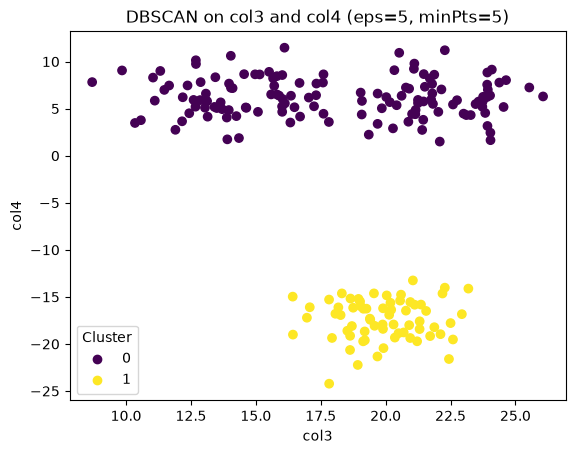

In [9]:
sc = plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.legend(*sc.legend_elements(), title="Cluster")
plt.title("DBSCAN on col3 and col4 (eps=5, minPts=5)")
plt.xlabel("col3")
plt.ylabel("col4")
plt.show()

### Q17

Use DBSCAN to cluster customers based on their purchasing behaviour (ex. frequency of purchases, average transaction amount)(Generate random dataset with min. 100 customers). Develop a program that analyses the clusters to identify different customer segments for targeted marketing

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

In [11]:
# Random customers (150): three behaviour groups + a few outliers
np.random.seed(42)
freq = np.concatenate([np.random.normal(5, 1.5, 50), np.random.normal(20, 2, 50),
                       np.random.normal(12, 1.5, 45), np.random.uniform(0, 30, 5)])
amount = np.concatenate([np.random.normal(2000, 300, 50), np.random.normal(500, 100, 50),
                         np.random.normal(1200, 150, 45), np.random.uniform(0, 3000, 5)])
df = pd.DataFrame({"purchase_frequency": freq.round(1), "avg_transaction": amount.round(0)})
print(df.head())
print("Shape:", df.shape)

   purchase_frequency  avg_transaction
0                 5.7           2235.0
1                 4.8           2185.0
2                 6.0           2365.0
3                 7.3           2068.0
4                 4.6           2254.0
Shape: (150, 2)


In [12]:
# Scale and run DBSCAN
X = StandardScaler().fit_transform(df)
model = DBSCAN(eps=0.35, min_samples=5)
df["Cluster"] = model.fit_predict(X)
print(df["Cluster"].value_counts())

Cluster
 1    50
 0    49
 2    44
-1     7
Name: count, dtype: int64


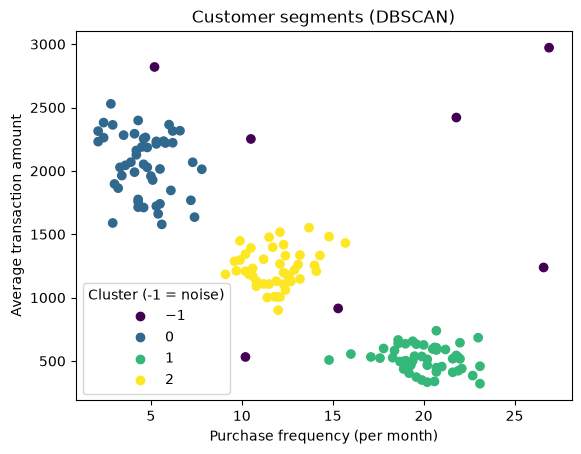

In [13]:
sc = plt.scatter(df["purchase_frequency"], df["avg_transaction"], c=df["Cluster"], cmap="viridis")
plt.legend(*sc.legend_elements(), title="Cluster (-1 = noise)")
plt.title("Customer segments (DBSCAN)")
plt.xlabel("Purchase frequency (per month)")
plt.ylabel("Average transaction amount")
plt.show()

In [14]:
# Analyse clusters and name segments for marketing
summary = df.groupby("Cluster").agg(customers=("purchase_frequency", "size"),
                                    avg_freq=("purchase_frequency", "mean"),
                                    avg_amount=("avg_transaction", "mean")).round(1)
print(summary)

for c, row in summary.iterrows():
    if c == -1:
        seg = "Outliers -> review individually"
    elif row.avg_freq >= 15:
        seg = "Frequent small buyers -> loyalty points, bundles"
    elif row.avg_amount >= 1500:
        seg = "Rare big spenders -> premium offers, reminders"
    else:
        seg = "Regular mid buyers -> cross-sell, discounts"
    print(f"Cluster {c}: {seg}")

         customers  avg_freq  avg_amount
Cluster                                 
-1               7      16.6      1878.6
 0              49       4.7      2056.5
 1              50      20.0       516.5
 2              44      11.9      1232.1
Cluster -1: Outliers -> review individually
Cluster 0: Rare big spenders -> premium offers, reminders
Cluster 1: Frequent small buyers -> loyalty points, bundles
Cluster 2: Regular mid buyers -> cross-sell, discounts


### Q18

Generate a data frame containing two features(Spending,features) for 100 data. Apply DBSCAN and do parametric analysis for eps value and show the impact on the performance of model via graph.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

In [16]:
# Two features for 100 rows ("features" in the question read as a second feature: Income)
X_raw, _ = make_blobs(n_samples=100, centers=[[30, 20], [70, 80], [80, 25]], cluster_std=7, random_state=42)
df = pd.DataFrame(X_raw, columns=["Spending", "Income"])
print(df.head())
X = StandardScaler().fit_transform(df)

    Spending     Income
0  83.312663  24.490198
1  24.125477  17.835513
2  56.568601  79.814403
3  26.645780  18.700387
4  73.177228  30.509592


In [17]:
# Try many eps values and record clusters, noise and silhouette
eps_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.5]
n_clusters, n_noise, sil = [], [], []
for eps in eps_values:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    k = len(set(lab)) - (1 if -1 in lab else 0)
    n_clusters.append(k)
    n_noise.append(list(lab).count(-1))
    sil.append(silhouette_score(X, lab) if k >= 2 else 0)   # silhouette needs >= 2 clusters
    print(f"eps={eps}: clusters={k}, noise={n_noise[-1]}, silhouette={sil[-1]:.3f}")

eps=0.1: clusters=1, noise=95, silhouette=0.000
eps=0.2: clusters=4, noise=23, silhouette=0.382
eps=0.3: clusters=3, noise=2, silhouette=0.676
eps=0.4: clusters=3, noise=0, silhouette=0.772
eps=0.5: clusters=3, noise=0, silhouette=0.772
eps=0.6: clusters=3, noise=0, silhouette=0.772
eps=0.8: clusters=3, noise=0, silhouette=0.772
eps=1.0: clusters=2, noise=0, silhouette=0.609
eps=1.5: clusters=1, noise=0, silhouette=0.000


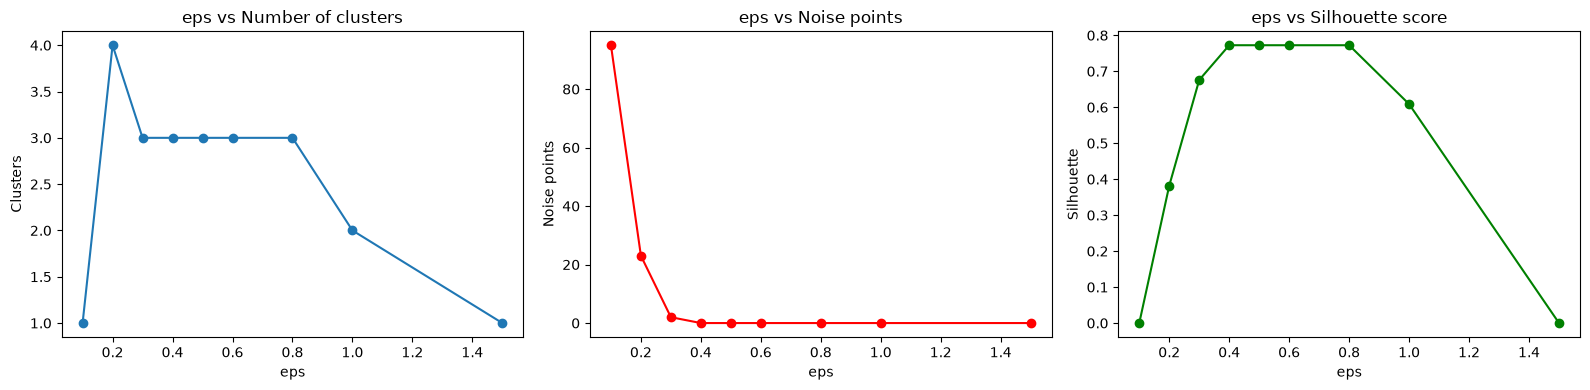

In [18]:
# Impact of eps on the model
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(eps_values, n_clusters, marker="o")
ax[0].set_title("eps vs Number of clusters")
ax[0].set_xlabel("eps")
ax[0].set_ylabel("Clusters")
ax[1].plot(eps_values, n_noise, marker="o", color="red")
ax[1].set_title("eps vs Noise points")
ax[1].set_xlabel("eps")
ax[1].set_ylabel("Noise points")
ax[2].plot(eps_values, sil, marker="o", color="green")
ax[2].set_title("eps vs Silhouette score")
ax[2].set_xlabel("eps")
ax[2].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

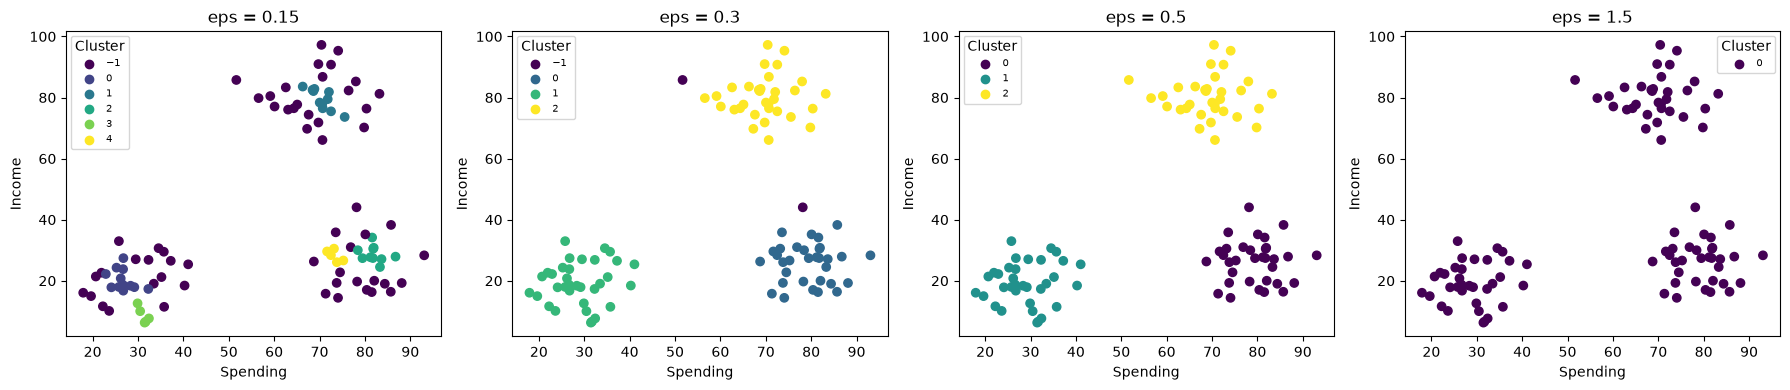

In [19]:
# Cluster plots for a few eps values
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for i, eps in enumerate([0.15, 0.3, 0.5, 1.5]):
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    sc = ax[i].scatter(df["Spending"], df["Income"], c=lab, cmap="viridis")
    ax[i].legend(*sc.legend_elements(), title="Cluster", fontsize=7)
    ax[i].set_title(f"eps = {eps}")
    ax[i].set_xlabel("Spending")
    ax[i].set_ylabel("Income")
plt.tight_layout()
plt.show()
# Small eps -> mostly noise; medium eps -> correct 3 clusters; large eps -> one big cluster.

### Q19

Generate a random dataset with 4 columns and use 1st and 3rd column as data to implement DBSCAN. What if eps is changed from 1 to 5? How it will affect the performance of the model? What is the impact of minPts on the performance of the model? Justify it with graph by changing minPts.

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import DBSCAN

In [21]:
# Random dataset with 4 columns (200 rows)
X_all, _ = make_blobs(n_samples=200, n_features=4, centers=4, cluster_std=1.5,
                      center_box=(-15, 15), random_state=42)
df = pd.DataFrame(X_all, columns=["col1", "col2", "col3", "col4"])
print(df.head())

# Use 1st and 3rd columns
X = df[["col1", "col3"]].values

        col1       col2       col3       col4
0  -3.400853  10.651509   4.372442   2.116323
1   9.032829  -5.911154  -8.483623 -10.341565
2  -6.847453 -13.121062 -12.228101   8.566211
3  11.208035  -8.519850 -11.480192 -11.440483
4   3.306250   6.614508 -15.071507  12.822529


eps=1: clusters=4, noise=44
eps=2: clusters=4, noise=2
eps=3: clusters=3, noise=0
eps=4: clusters=3, noise=0
eps=5: clusters=3, noise=0


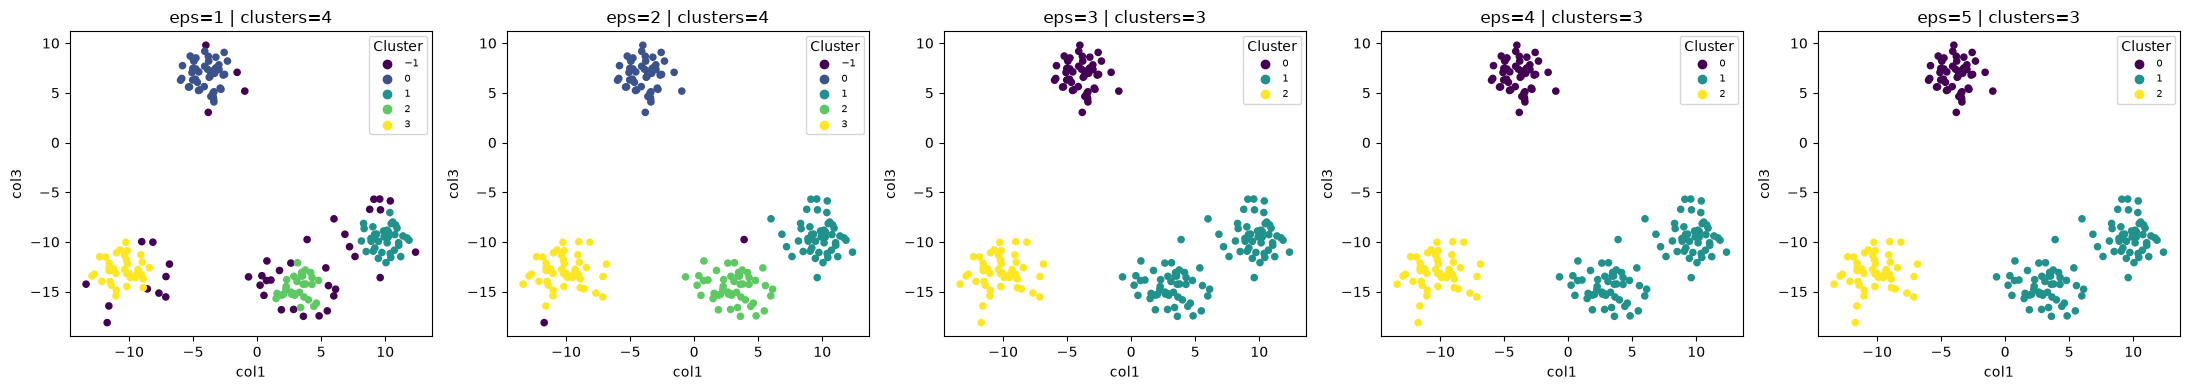

In [22]:
# Part 1: eps from 1 to 5 (minPts fixed = 5)
fig, ax = plt.subplots(1, 5, figsize=(22, 4))
for i, eps in enumerate([1, 2, 3, 4, 5]):
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    k = len(set(lab)) - (1 if -1 in lab else 0)
    print(f"eps={eps}: clusters={k}, noise={list(lab).count(-1)}")
    sc = ax[i].scatter(X[:, 0], X[:, 1], c=lab, cmap="viridis", s=20)
    ax[i].legend(*sc.legend_elements(), title="Cluster", fontsize=7)
    ax[i].set_title(f"eps={eps} | clusters={k}")
    ax[i].set_xlabel("col1")
    ax[i].set_ylabel("col3")
plt.tight_layout()
plt.show()

In [23]:
# Part 2: change minPts (eps fixed = 2)
min_pts = [2, 5, 10, 15, 20, 30]
clusters, noise = [], []
for m in min_pts:
    lab = DBSCAN(eps=2, min_samples=m).fit_predict(X)
    clusters.append(len(set(lab)) - (1 if -1 in lab else 0))
    noise.append(list(lab).count(-1))
    print(f"minPts={m}: clusters={clusters[-1]}, noise={noise[-1]}")

minPts=2: clusters=4, noise=1
minPts=5: clusters=4, noise=2
minPts=10: clusters=4, noise=3
minPts=15: clusters=4, noise=7
minPts=20: clusters=4, noise=18
minPts=30: clusters=3, noise=88


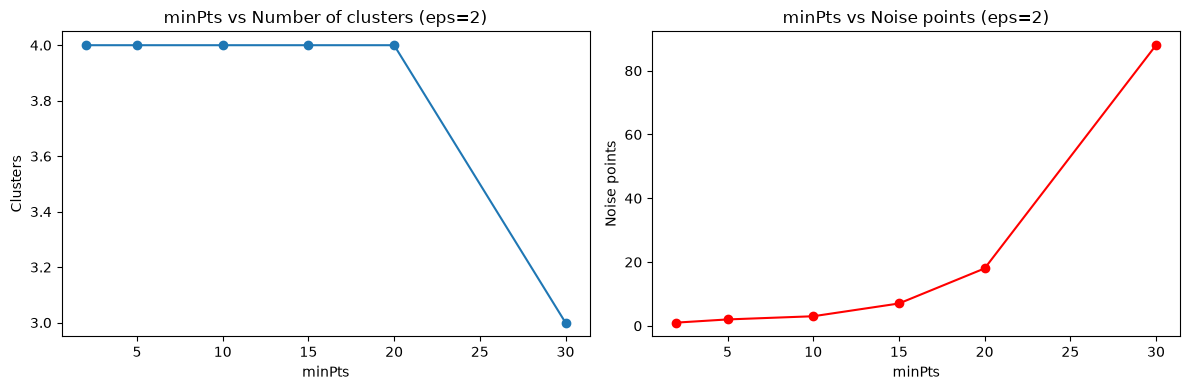

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(min_pts, clusters, marker="o")
ax[0].set_title("minPts vs Number of clusters (eps=2)")
ax[0].set_xlabel("minPts")
ax[0].set_ylabel("Clusters")
ax[1].plot(min_pts, noise, marker="o", color="red")
ax[1].set_title("minPts vs Noise points (eps=2)")
ax[1].set_xlabel("minPts")
ax[1].set_ylabel("Noise points")
plt.tight_layout()
plt.show()
# Bigger eps -> clusters merge and noise drops. Bigger minPts -> stricter core rule -> more noise.

### Q20

Generate random dataset for mall_customer dataset with features like Customer, Genre, Age, Annual Imcome, Spending Score. Consider minimum 200 random samples for analysis. Apply DBSCAN as well as agglomerative clustering and generate the dendrogram. Plot points in each cluster for DBSCAN with different colours.

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [26]:
# Random mall customers (200), income/score drawn around 5 typical groups
np.random.seed(42)
centers = [(25, 20), (25, 80), (55, 50), (85, 15), (85, 85)]
income, score = [], []
for cx, cy in centers:
    income += list(np.random.normal(cx, 6, 40))
    score += list(np.random.normal(cy, 6, 40))
df = pd.DataFrame({
    "CustomerID": range(1, 201),
    "Genre": np.random.choice(["Male", "Female"], 200),
    "Age": np.random.randint(18, 70, 200),
    "Annual Income (k$)": np.round(income, 1),
    "Spending Score (1-100)": np.clip(np.round(score), 1, 100),
})
print(df.head())
print("Shape:", df.shape)

   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   41                28.0                    24.0
1           2    Male   19                24.2                    21.0
2           3    Male   62                28.9                    19.0
3           4    Male   43                34.1                    18.0
4           5  Female   31                23.6                    11.0
Shape: (200, 5)


In [27]:
# Use income and spending score, scale them
X = StandardScaler().fit_transform(df[["Annual Income (k$)", "Spending Score (1-100)"]])

# DBSCAN
db_labels = DBSCAN(eps=0.3, min_samples=5).fit_predict(X)
df["DBSCAN"] = db_labels
print("DBSCAN clusters:", len(set(db_labels)) - (1 if -1 in db_labels else 0),
      "| noise:", list(db_labels).count(-1))

DBSCAN clusters: 5 | noise: 3


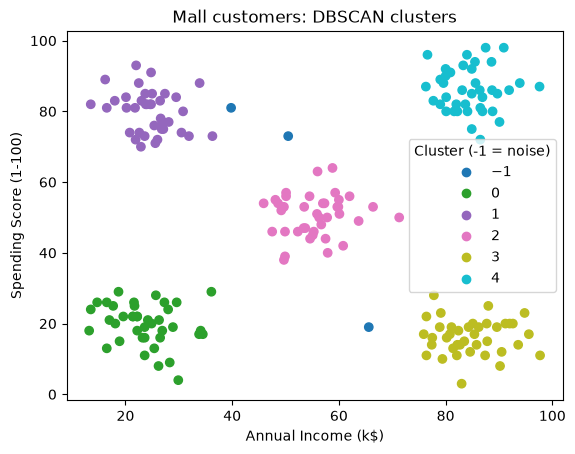

In [28]:
# Plot DBSCAN clusters with different colours
sc = plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], c=db_labels, cmap="tab10")
plt.legend(*sc.legend_elements(), title="Cluster (-1 = noise)")
plt.title("Mall customers: DBSCAN clusters")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

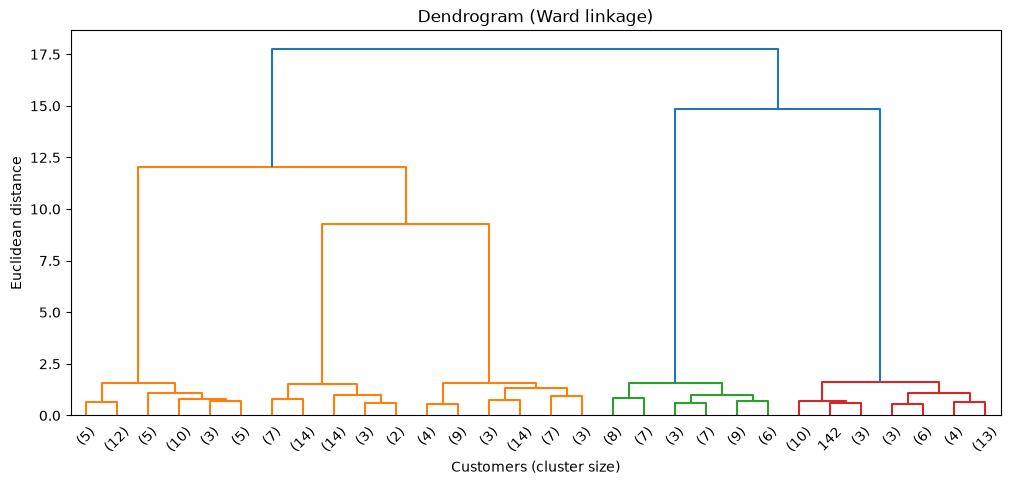

In [29]:
# Dendrogram (ward linkage)
plt.figure(figsize=(12, 5))
dendrogram(linkage(X, method="ward"), truncate_mode="lastp", p=30)
plt.title("Dendrogram (Ward linkage)")
plt.xlabel("Customers (cluster size)")
plt.ylabel("Euclidean distance")
plt.show()

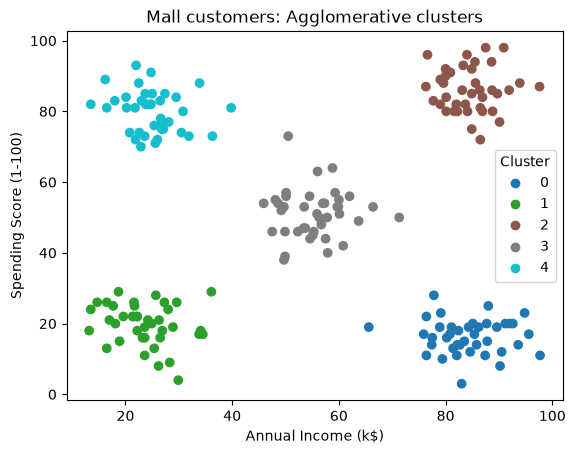

        Age  Annual Income (k$)  Spending Score (1-100)
Agglo                                                  
0      38.8                84.3                    16.4
1      44.2                23.7                    19.8
2      43.3                84.5                    86.2
3      40.0                55.4                    51.1
4      46.8                25.1                    79.9


In [30]:
# Agglomerative clustering with 5 clusters (from dendrogram cut)
agg = AgglomerativeClustering(n_clusters=5, linkage="ward")
df["Agglo"] = agg.fit_predict(X)
sc = plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], c=df["Agglo"], cmap="tab10")
plt.legend(*sc.legend_elements(), title="Cluster")
plt.title("Mall customers: Agglomerative clusters")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()
print(df.groupby("Agglo")[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].mean().round(1))